# Análisis de Transacciones — Mendel (CVC)

Notebook de análisis exploratorio (EDA) sobre el **gasto corporativo** registrado en Mendel, exportado por el pipeline de descarga (`mendel-api/download/download_all.php`).

## Contexto

- **Fuente:** `transactions.csv` — una fila por transacción (36 columnas). Está junto a este notebook (`mendel/data/`).
- **Cobertura:** 2025-08 → 2026-08 (13 meses).
- **Entidades relacionadas** (mismos CSV): `people`, `cost_centers`, `budgets`, `billing_documents`, `companies`.

## Preguntas que responde este notebook

| Pregunta | Sección |
|---|---|
| ¿Cuánto se gastó y cómo evoluciona en el tiempo? | §2–3 |
| ¿Quién gasta? (pagadores) | §4 |
| ¿En qué y en dónde se gasta? (categorías, comercios, canales) | §5–6 |
| ¿Cómo se imputa contablemente? (centro de costo y splits) | §7 |
| ¿Qué pasa con estados, aprobaciones y devoluciones? | §8 |
| ¿Presupuesto vs gasto real? | §9 |
| ¿Impuestos y documentación fiscal? | §10 |

> ⚠️ Los montos son **nominales en ARS**, sin ajuste por inflación: no son directamente comparables entre meses lejanos sin deflactar.


In [4]:
# ─────────────────────────────────────────────────────────────
# 1. Imports, rutas y utilidades
# ─────────────────────────────────────────────────────────────
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def find_data_dir() -> Path:
    """Localiza el directorio con transactions.csv desde el notebook hacia arriba."""
    roots = [Path.cwd().resolve()]
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        roots.insert(0, Path(nb).resolve().parent)

    rels = (Path(), Path("data"), Path("data") / "mendel", Path("mendel") / "data")
    for root in roots:
        for base in [root, *root.parents]:
            for rel in rels:
                cand = base / rel
                if (cand / "transactions.csv").exists():
                    return cand
    raise FileNotFoundError("No se encuentra transactions.csv junto al notebook")


DATA_DIR = find_data_dir()
print("Directorio de datos:", DATA_DIR)


def load(name: str) -> pd.DataFrame:
    df = pd.read_csv(DATA_DIR / name, low_memory=False)
    print(f"  {name:26s} {len(df):>6,} filas × {df.shape[1]:>2} cols")
    return df


def to_bool(s: pd.Series) -> pd.Series:
    """Normaliza booleanos que llegan como bool o como str 'true'/'false'."""
    def _b(v):
        if isinstance(v, bool):
            return v
        if isinstance(v, str):
            return v.strip().lower() in {"true", "1"}
        return bool(v) if pd.notna(v) else False
    return s.map(_b).fillna(False)


Directorio de datos: /Users/mgarcia/Desktop/proyectos/docflow/mendel/data


In [5]:
# ─────────────────────────────────────────────────────────────
# 2. Carga de transacciones y normalización de tipos
# ─────────────────────────────────────────────────────────────
tx = load("transactions.csv")

# Montos numéricos
for c in ["amount", "signedAmount"]:
    tx[c] = pd.to_numeric(tx[c], errors="coerce")

# Booleanos
for c in ["cancelled", "editable", "archived", "paymentTicketAttached"]:
    if c in tx.columns:
        tx[c] = to_bool(tx[c])

# Fechas y período
tx["paymentDate"] = pd.to_datetime(tx["paymentDate"], errors="coerce")
tx["month"] = tx["month"].astype(str)

print(f"Rango de fechas: {tx['paymentDate'].min():%Y-%m-%d} → {tx['paymentDate'].max():%Y-%m-%d}")
print(f"paymentDate nulos: {int(tx['paymentDate'].isna().sum())} | amount nulos: {int(tx['amount'].isna().sum())}")
tx.head(3)


  transactions.csv            4,711 filas × 36 cols
Rango de fechas: 2025-08-04 → 2026-10-09
paymentDate nulos: 0 | amount nulos: 0


,uniqueCode,shortId,companyCode,companyName,description,amount,signedAmount,sign,currencyCode,type,...,paymentTicketAttached,budgetCode,budgetName,costCenterCode,costCenterName,expenseCategoryCode,expenseCategoryDescription,approvalWorkflowStatus,purchaseSplits,month
0,2d2c9343-6076-40cb-b052-e502a889a3e2,2D2C9343,d24a9611-2a83-4760-af7e-5c66790aacee,CVC SA,FARMACIA SILVA,"73,122.60","73,122.60",-1,ARS,PURCHASE,...,True,45fffbb3-0fc5-4b62-aa3a-cb298d3ec2dd,Equipo 1,617578e0-4aac-4191-b410-2782d396d1c2,Indirectos,35,Salud,AUTHORIZED,"[{""amount"":73122.6,""costCenter"":{""externalId"":...",2025-08
1,2e1f7d6c-dfab-4714-a9bc-781d84677562,2E1F7D6C,d24a9611-2a83-4760-af7e-5c66790aacee,CVC SA,DIARCO SA SUC JUNIN,"127,911.89","127,911.89",-1,ARS,PURCHASE,...,True,45fffbb3-0fc5-4b62-aa3a-cb298d3ec2dd,Equipo 1,617578e0-4aac-4191-b410-2782d396d1c2,Indirectos,429223d9-b636-11ec-92b1-06d0eba98f18,Supermercados,AUTHORIZED,"[{""amount"":127911.89,""costCenter"":{""externalId...",2025-08
2,44bb14da-815c-4473-8d45-3ef857990766,44BB14DA,d24a9611-2a83-4760-af7e-5c66790aacee,CVC SA,FARMACIA SILVA,"73,122.00","73,122.00",-1,ARS,PURCHASE,...,False,NaN,NaN,617578e0-4aac-4191-b410-2782d396d1c2,Indirectos,35,Salud,NaN,"[{""amount"":73122,""costCenter"":{""externalId"":""C...",2025-08


## 1. Rango de análisis (fechas)

Acá se define el **período** sobre el que corre todo el análisis (secciones siguientes). Cambiá `FECHA_DESDE` / `FECHA_HASTA` en la celda de código y **volvé a ejecutar desde esta sección** (o *Run All*) para recalcular todo.

- Formato `YYYY-MM-DD`; **ambos extremos son inclusivos**.
- Dejá `""` (vacío) en un extremo para no limitarlo (ej. `FECHA_DESDE = ""` = desde el inicio).
- Si el corte cae a mitad de mes, ese mes aparece **parcial** en los gráficos mensuales.
- Los montos siguen siendo nominales en ARS (ver nota del título).


In [6]:
# ─────────────────────────────────────────────────────────────
# 1. Rango de análisis — FECHA_DESDE / FECHA_HASTA (inclusivos)
#    Editar estas fechas acota TODAS las secciones siguientes.
#    "" = sin límite en ese extremo.
# ─────────────────────────────────────────────────────────────
FECHA_DESDE = "2026-01-01"
FECHA_HASTA = "2026-09-01"

# paymentDate es tz-aware (UTC): se alinean los límites a su misma zona.
_tz = tx["paymentDate"].dt.tz
_desde = pd.Timestamp(FECHA_DESDE) if FECHA_DESDE else None
_hasta = (pd.Timestamp(FECHA_HASTA) + pd.Timedelta(days=1)) if FECHA_HASTA else None
if _tz is not None:
    _desde = _desde.tz_localize(_tz) if _desde is not None else None
    _hasta = _hasta.tz_localize(_tz) if _hasta is not None else None

n_total = len(tx)
if _desde is not None:
    tx = tx[tx["paymentDate"] >= _desde]
if _hasta is not None:
    tx = tx[tx["paymentDate"] < _hasta]

print(f"Rango de análisis: {FECHA_DESDE or 'inicio de datos'} → {FECHA_HASTA or 'fin de datos'}")
print(f"Transacciones en rango: {len(tx):,} de {n_total:,} ({100 * len(tx) / n_total:.1f}%)")
print("Meses incluidos:", sorted(tx["month"].unique()))


Rango de análisis: 2026-01-01 → 2026-09-01
Transacciones en rango: 3,369 de 4,711 (71.5%)
Meses incluidos: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


## 2. Perfilado y calidad de datos

Antes de analizar conviene ver dimensiones, nulos y la distribución de las variables clave (tipo, estado, canal, modo, ubicación, aprobación).


In [7]:
# ─────────────────────────────────────────────────────────────
# 2. Perfilado rápido de calidad
# ─────────────────────────────────────────────────────────────
print("═══ Dimensiones ═══")
print(f"Filas: {len(tx):,} | Columnas: {tx.shape[1]} | "
      f"Meses: {tx['month'].min()} → {tx['month'].max()} ({tx['month'].nunique()})")

print("\n═══ Valores nulos por columna ═══")
nul = tx.isna().sum()
nul = nul[nul > 0].sort_values(ascending=False)
print(nul.to_string() if len(nul) else "  Sin nulos")

print("\n═══ Distribución de variables clave ═══")
for c in ["type", "transactionStatus", "paymentChannel",
          "paymentLocationType", "paymentMode", "approvalWorkflowStatus"]:
    print(f"\n[{c}]")
    print(tx[c].value_counts(dropna=False).to_string())


═══ Dimensiones ═══
Filas: 3,369 | Columnas: 36 | Meses: 2026-01 → 2026-09 (9)

═══ Valores nulos por columna ═══
notes                     101
approvalWorkflowStatus     96
budgetCode                 88
budgetName                 88
costCenterCode             16
costCenterName             16
sellerCategory              1

═══ Distribución de variables clave ═══

[type]
type
PURCHASE      3357
REFUND           9
ADJUSTMENT       3

[transactionStatus]
transactionStatus
CONFIRMED    3281
DECLINED       84
EXPIRED         3
PENDING         1

[paymentChannel]
paymentChannel
PHYSICAL    2981
ONLINE       388

[paymentLocationType]
paymentLocationType
LOCAL            3349
INTERNATIONAL      20

[paymentMode]
paymentMode
PHYSICAL_CARD    3369

[approvalWorkflowStatus]
approvalWorkflowStatus
AUTHORIZED            3229
NaN                     96
SUBMITTED               18
PARTIAL_AUTHORIZED      14
PENDING_SUBMISSION       7
UNAUTHORIZED             4
PENDING                  1


## 3. KPIs globales del período

Indicadores de cabecera: volumen, monto total (separando débitos de créditos/devoluciones), ticket promedio y diversidad de actores.


In [8]:
# ─────────────────────────────────────────────────────────────
# 3. KPIs globales
# ─────────────────────────────────────────────────────────────
gasto = tx.loc[tx["sign"] < 0, "amount"].sum()      # débitos (gasto)
creditos = tx.loc[tx["sign"] > 0, "amount"].sum()   # créditos / devoluciones

kpis = pd.Series({
    "Transacciones totales": len(tx),
    "Gasto total (débitos)": gasto,
    "Créditos / devoluciones": creditos,
    "Gasto neto": gasto - creditos,
    "Ticket promedio": tx["amount"].mean(),
    "Ticket mediana": tx["amount"].median(),
    "Ticket máximo": tx["amount"].max(),
    "Pagadores distintos": tx["paymentPayerFullName"].nunique(),
    "Comercios distintos": tx["sellerName"].nunique(),
    "Centros de costo (tx)": tx["costCenterName"].nunique(),
    "Con ticket adjunto": int(tx["paymentTicketAttached"].sum()),
    "Canceladas": int(tx["cancelled"].sum()),
})

out = kpis.to_frame("Valor")
out["Valor"] = out["Valor"].map(
    lambda v: f"{v:,.0f}" if isinstance(v, (int, float)) and not np.isnan(v) else v
)
out


,Valor
Transacciones totales,"3,369"
Gasto total (débitos),"174,878,879"
Créditos / devoluciones,"978,824"
Gasto neto,"173,900,055"
Ticket promedio,"52,199"
Ticket mediana,"25,230"
Ticket máximo,"2,136,974"
Pagadores distintos,61
Comercios distintos,785
Centros de costo (tx),5


## 4. Evolución temporal

La columna `month` (YYYY-MM) viene precargada. El primer mes (2025-08) puede estar **incompleto** porque es el inicio de la descarga.


           n        total      avg
month                             
2026-01  368  $20,149,615  $54,754
2026-02  286  $10,730,041  $37,518
2026-03  380  $18,918,089  $49,784
2026-04  544  $23,111,437  $42,484
2026-05  434  $22,565,487  $51,994
2026-06  427  $23,997,148  $56,199
2026-07  450  $25,495,949  $56,658
2026-08  456  $30,011,039  $65,814
2026-09   24     $878,898  $36,621


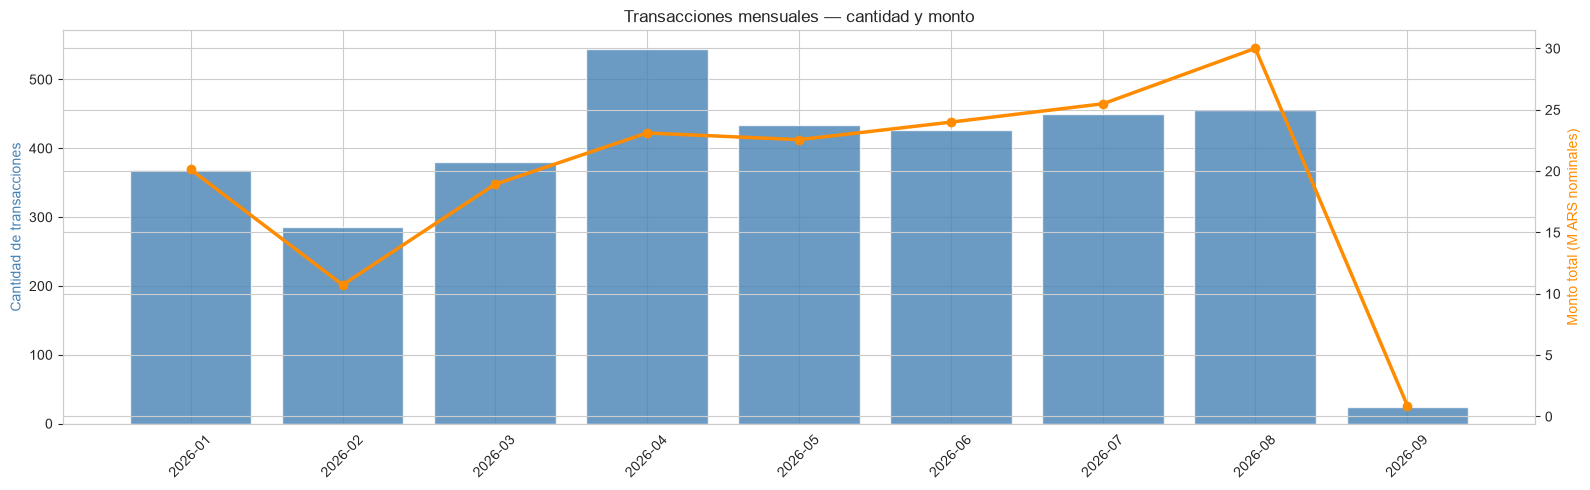

In [9]:
# ─────────────────────────────────────────────────────────────
# 4. Evolución mensual (cantidad y monto)
# ─────────────────────────────────────────────────────────────
monthly = (tx.groupby("month")
             .agg(n=("uniqueCode", "count"),
                  total=("amount", "sum"),
                  avg=("amount", "mean"))
             .sort_index())
print(monthly.assign(total=lambda d: d["total"].map("${:,.0f}".format),
                     avg=lambda d: d["avg"].map("${:,.0f}".format)).to_string())

fig, ax1 = plt.subplots(figsize=(16, 5))
ax1.bar(monthly.index, monthly["n"], color="steelblue", alpha=.8, label="Cantidad")
ax1.set_ylabel("Cantidad de transacciones", color="steelblue")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["total"] / 1e6, "o-", color="darkorange", lw=2.5,
         label="Monto (M ARS)")
ax2.set_ylabel("Monto total (M ARS nominales)", color="darkorange")
ax1.set_title("Transacciones mensuales — cantidad y monto")
plt.tight_layout()
plt.show()


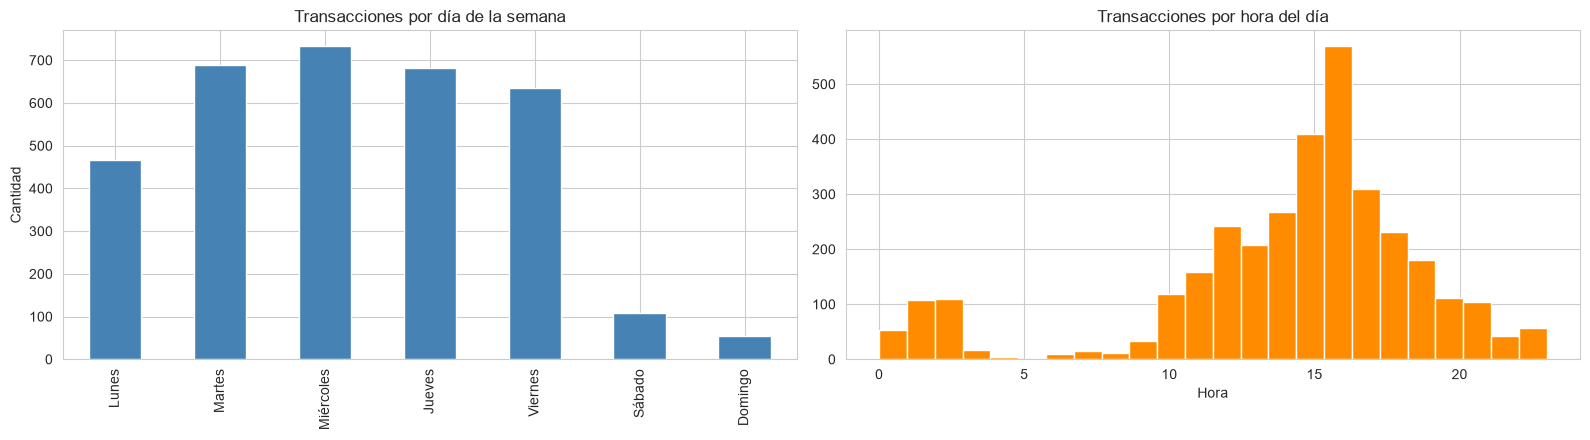

In [10]:
# ─────────────────────────────────────────────────────────────
# 4b. Estacionalidad: día de la semana y hora del día
# ─────────────────────────────────────────────────────────────
DOW_ES = {"Monday": "Lunes", "Tuesday": "Martes", "Wednesday": "Miércoles",
          "Thursday": "Jueves", "Friday": "Viernes", "Saturday": "Sábado",
          "Sunday": "Domingo"}
order_es = list(DOW_ES.values())

dow = (tx["paymentDate"].dt.day_name().map(DOW_ES)
         .value_counts().reindex(order_es))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
dow.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Transacciones por día de la semana")
axes[0].set_ylabel("Cantidad"); axes[0].set_xlabel("")

tx["paymentDate"].dt.hour.hist(bins=24, ax=axes[1], color="darkorange",
                               edgecolor="white")
axes[1].set_title("Transacciones por hora del día")
axes[1].set_xlabel("Hora")

plt.tight_layout(); plt.show()


## 5. ¿Quién gasta? (pagadores)

`paymentPayerFullName` identifica a la persona que pagó. Es la primera pista para la imputación contable (ver docs de heurística).


═══ Top 15 pagadores por monto total ═══
                               n        total       avg  con_ticket
paymentPayerFullName                                               
Martin Ojea Quintana          61  $29,202,468  $478,729          39
Gustavo Ayala                309  $21,175,287   $68,528         245
Juan Jose Echaire            268   $9,253,617   $34,528         258
Claudio Marcelo Zvicer       168   $8,427,897   $50,166         163
Juan Pablo Maldonado         141   $7,294,955   $51,737         124
Edgardo Barnetche             79   $6,791,784   $85,972          62
Martin Miguel Fernandez      170   $6,465,557   $38,033         167
Sebastián Carlos Cordoba     139   $5,325,240   $38,311         123
Jorge Armando                134   $4,693,843   $35,029         134
Franco Caviglia              165   $4,546,780   $27,556         164
Carolina Andrea Vinciguerra   91   $4,517,012   $49,637          68
Luis Alberto Lovizzio         71   $4,353,718   $61,320          69
Luis Ge

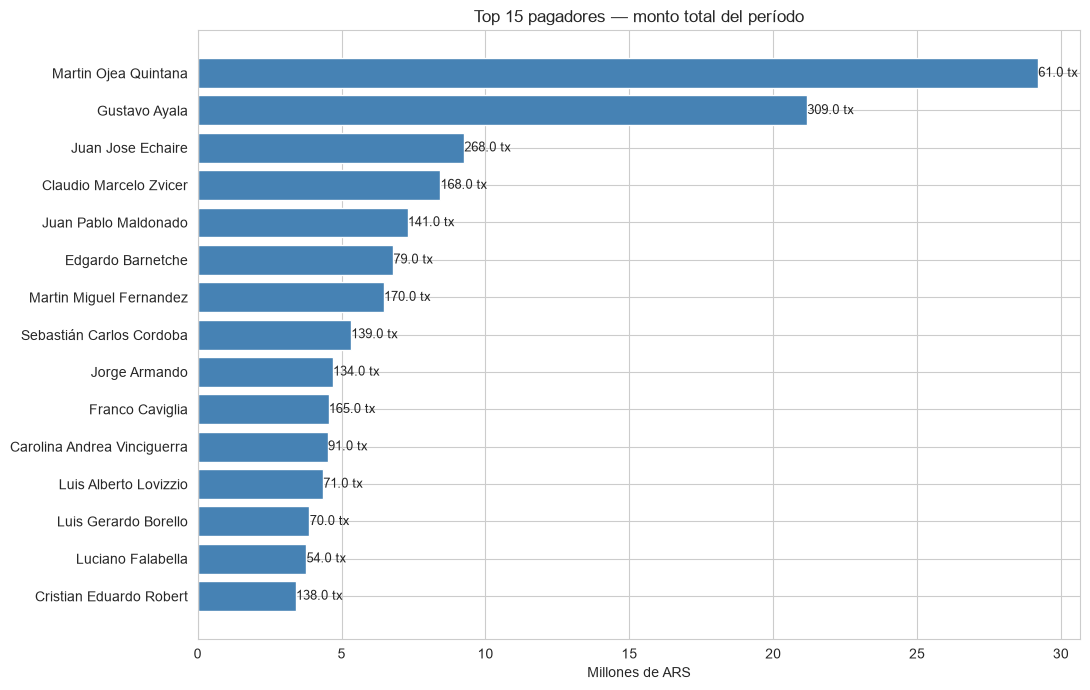

In [11]:
# ─────────────────────────────────────────────────────────────
# 5. Top pagadores
# ─────────────────────────────────────────────────────────────
payer = (tx.groupby("paymentPayerFullName")
           .agg(n=("uniqueCode", "count"),
                total=("amount", "sum"),
                avg=("amount", "mean"),
                con_ticket=("paymentTicketAttached", "sum"))
           .sort_values("total", ascending=False))
top = payer.head(15)
print("═══ Top 15 pagadores por monto total ═══")
print(top.assign(total=lambda d: d["total"].map("${:,.0f}".format),
                 avg=lambda d: d["avg"].map("${:,.0f}".format)).to_string())

# Gráfico horizontal (monto) con cantidad de tx como etiqueta
d = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(d.index, d["total"] / 1e6, color="steelblue")
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["total"] / 1e6 + .01, i, f"{r['n']:,} tx", va="center", fontsize=9)
ax.set_xlabel("Millones de ARS")
ax.set_title("Top 15 pagadores — monto total del período")
plt.tight_layout(); plt.show()


In [12]:
# ─────────────────────────────────────────────────────────────
# 5b. Top pagadores × canal de pago (monto)
# ─────────────────────────────────────────────────────────────
cross = (tx[tx["paymentPayerFullName"].isin(top.head(10).index)]
           .pivot_table(index="paymentPayerFullName", columns="paymentChannel",
                        values="amount", aggfunc="sum", fill_value=0))
print("Monto por pagador y canal (ARS):")
print(cross.map("${:,.0f}".format).to_string())


Monto por pagador y canal (ARS):
paymentChannel                 ONLINE     PHYSICAL
paymentPayerFullName                              
Claudio Marcelo Zvicer     $3,489,409   $4,938,488
Edgardo Barnetche            $394,429   $6,397,355
Franco Caviglia               $37,767   $4,509,013
Gustavo Ayala                $158,592  $21,016,695
Jorge Armando                $101,659   $4,592,184
Juan Jose Echaire            $388,345   $8,865,273
Juan Pablo Maldonado       $2,733,993   $4,560,962
Martin Miguel Fernandez        $3,000   $6,462,557
Martin Ojea Quintana      $27,936,414   $1,266,053
Sebastián Carlos Cordoba      $11,050   $5,314,190


## 6. ¿En qué se gasta? (categorías y comercios)

- `sellerCategory` = categoría del **comercio emisor** (MCC de la tarjeta: ej. *Gasolineras*, *Restaurantes*).
- `expenseCategoryDescription` = categoría **interna de gasto** asignada (ej. *Salud*, *Vehículos*). No son equivalentes.


═══ Categorías de comercio (MCC) por monto ═══
                                n        total
sellerCategory                                
Gasolineras                  1157  $67,564,406
Restaurantes                  421  $13,456,219
Supermercados                 332   $9,398,881
Otros Comercios                44   $7,918,572
Servicios de Almacenamiento   169   $5,533,234
Comida Rápida                 287   $5,334,865
Educación Básica                4   $5,304,000
Agencias de Viajes              8   $4,909,879
Autopartes                     40   $4,375,952
Entretenimiento                 4   $4,370,214
Hospedaje                      26   $4,342,407
Hoteles                        36   $4,026,516
Servicios de Correo y Carga   108   $2,903,313
Otros Servicios Comerciales    20   $2,872,894
Electrodomésticos               5   $2,186,733


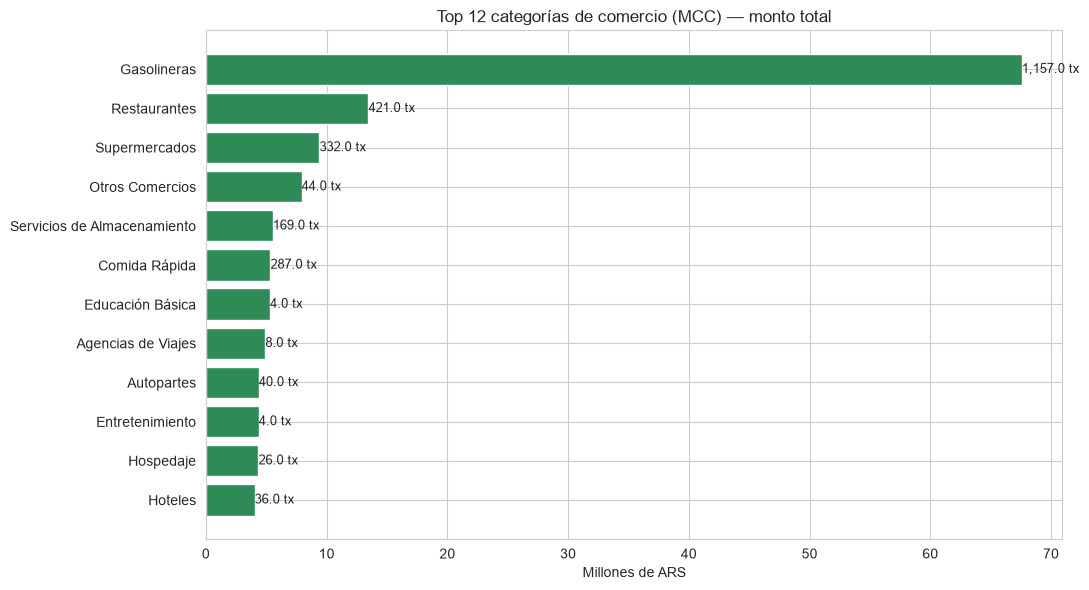


═══ Top 15 comercios por monto ═══
                             n        total
sellerName                                 
HERRERO SRL                 99  $10,193,141
Starlink                     6   $8,460,000
YPF                        196   $8,344,103
ALTOS DEL PARQUE           326   $6,166,230
WWW.MIAMI-IT.NET             7   $5,674,461
CAJA DE SEGURIDAD SOCIAL     2   $4,273,948
Shell                       55   $4,244,903
Starlink Argentina           3   $4,145,085
EST DE SERVICIO EL PAS      84   $4,142,942
ECO SERVICIOS ALCIATI       41   $3,662,465
ROMA COMBUSTIBLES SA        46   $3,188,552
PERGAMINO AUTOMOTORES SA    10   $2,696,126
DLO*Starlink Argentina       2   $2,485,995
WYNDHAM NORDELTA TIGRE BS    9   $2,478,075
Holiday Inn                 10   $2,044,200


In [13]:
# ─────────────────────────────────────────────────────────────
# 6. Categoría del comercio (sellerCategory / MCC)
# ─────────────────────────────────────────────────────────────
cat = (tx.groupby("sellerCategory")
         .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
         .sort_values("total", ascending=False))
print("═══ Categorías de comercio (MCC) por monto ═══")
print(cat.head(15).assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())

fig, ax = plt.subplots(figsize=(11, 6))
d = cat.head(12).iloc[::-1]
ax.barh(d.index, d["total"] / 1e6, color="seagreen")
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["total"] / 1e6 + .01, i, f"{r['n']:,} tx", va="center", fontsize=9)
ax.set_xlabel("Millones de ARS")
ax.set_title("Top 12 categorías de comercio (MCC) — monto total")
plt.tight_layout(); plt.show()

# Top comercios
sel = (tx.groupby("sellerName")
         .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
         .sort_values("total", ascending=False))
print("\n═══ Top 15 comercios por monto ═══")
print(sel.head(15).assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())


In [14]:
# ─────────────────────────────────────────────────────────────
# 6b. Categoría interna de gasto (expenseCategoryDescription)
# ─────────────────────────────────────────────────────────────
conc = (tx.groupby("expenseCategoryDescription")
          .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
          .sort_values("total", ascending=False))
print(conc.head(15).assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())


                                         n        total
expenseCategoryDescription                             
Gasolineras                            983  $65,192,792
Restaurantes                          1267  $30,326,015
Vehículos y Mantenimiento              109  $10,542,959
Otros Comercios                         79   $8,926,120
Hospedaje                               51   $8,265,329
Supermercados                          240   $8,108,675
Licencias y Servicios IT                32   $7,391,478
Agencias de Viajes                       7   $4,912,878
Construcción y Mantenimiento            77   $4,068,355
Educación                                4   $3,980,271
Transporte de Pasajeros y Carga        118   $3,631,747
Servicios de Correo y Carga            100   $3,325,046
Equipos de Oficina y Suministros        72   $3,126,105
Honorarios y Servicios Profesionales    12   $2,968,102
Otros                                   24   $2,358,851


## 7. Canales, modo y ubicación de pago

Muestra cómo se compone el gasto: canal físico/online, modo de tarjeta y origen local/internacional.


═══ Canal de pago ═══
                   n         total
paymentChannel                    
PHYSICAL        2981  $135,537,524
ONLINE           388   $40,320,178

═══ Modo de pago ═══
                  n         total
paymentMode                      
PHYSICAL_CARD  3369  $175,857,702

═══ Ubicación ═══
                        n         total
paymentLocationType                    
LOCAL                3349  $169,423,369
INTERNATIONAL          20    $6,434,333



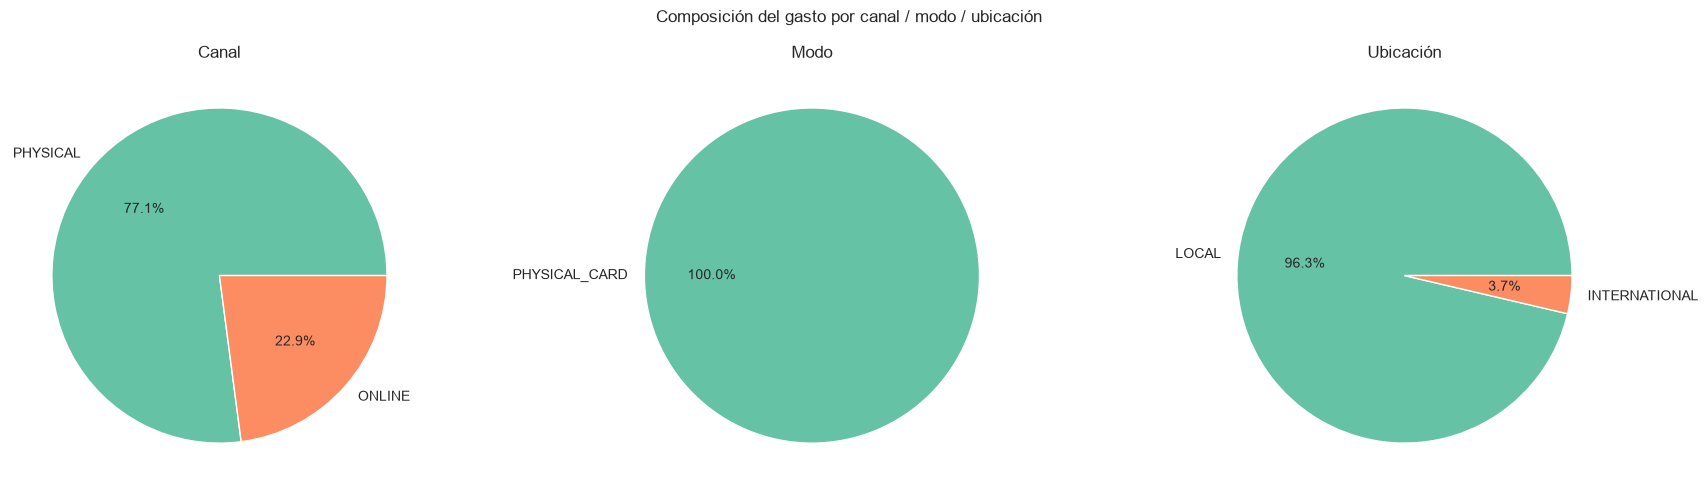

In [15]:
# ─────────────────────────────────────────────────────────────
# 7. Canal, modo y ubicación de pago
# ─────────────────────────────────────────────────────────────
def dim_summary(col, title):
    g = (tx.groupby(col)
           .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
           .sort_values("total", ascending=False))
    print(f"═══ {title} ═══")
    print(g.assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())
    print()
    return g

channel = dim_summary("paymentChannel", "Canal de pago")
mode    = dim_summary("paymentMode", "Modo de pago")
location = dim_summary("paymentLocationType", "Ubicación")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, g, t in [(axes[0], channel, "Canal"), (axes[1], mode, "Modo"),
                 (axes[2], location, "Ubicación")]:
    g["total"].plot(kind="pie", autopct="%1.1f%%", ax=ax,
                    colors=sns.color_palette("Set2", len(g)))
    ax.set_title(t); ax.set_ylabel("")
plt.suptitle("Composición del gasto por canal / modo / ubicación")
plt.tight_layout(); plt.show()


In [16]:
# ─────────────────────────────────────────────────────────────
# 7b. Gastos internacionales (detalle de comercios)
# ─────────────────────────────────────────────────────────────
inter = tx[tx["paymentLocationType"] == "INTERNATIONAL"]
print(f"Transacciones internacionales: {len(inter):,} "
      f"({100 * len(inter) / len(tx):.2f}% del total)")
print(inter.groupby("sellerName")["amount"]
           .agg(["count", "sum"]).sort_values("sum", ascending=False)
           .head(10).to_string())


Transacciones internacionales: 20 (0.59% del total)
                        count          sum
sellerName                                
WWW.MIAMI-IT.NET            7 5,674,460.67
READ - MEETING MANAGER      1   393,777.75
ANTHROPIC* CLAUDE SUB       6   172,963.56
Anthropic                   3    90,876.46
LICENCIA 06329              1    58,885.76
Adobe                       2    43,368.82


## 8. Imputación contable: centro de costo y splits

Cada transacción trae una columna `costCenterName` (imputación declarada) y un JSON `purchaseSplits[]` con el detalle contable (cuenta + CC + monto imputado). Esta sección explota ese JSON para reconstruir la imputación real.


Tx con 0 / 1 / >1 splits: {0: 15, 1: 3354}

═══ Imputación por CC (según el split contable) ═══
               n        total
splitCC                      
Indirectos   731  $72,568,234
Servicios   1807  $69,820,762
Nuevas       732  $29,065,942
Chaperia      81   $2,930,593
Repuestos      2      $77,842


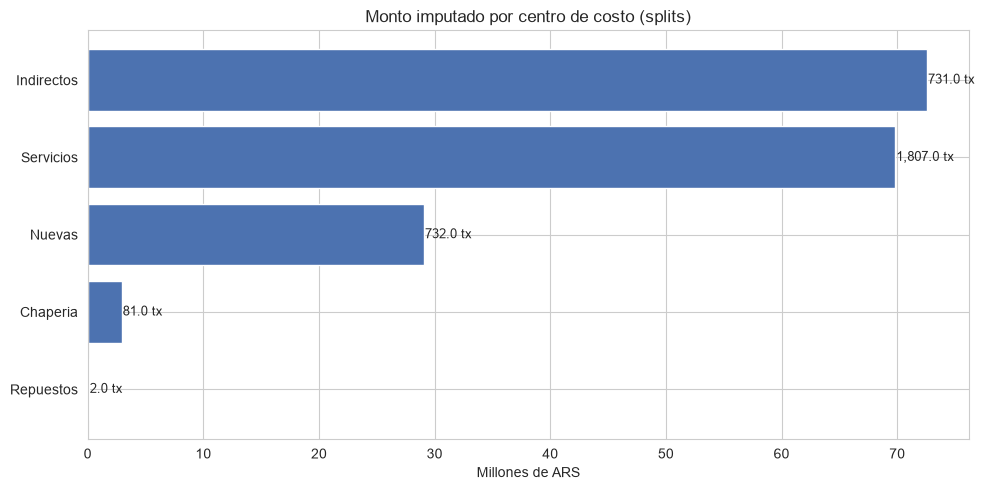


Coincidencia CC a nivel tx vs split: 99.97% (discrepancias: 1)


In [17]:
# ─────────────────────────────────────────────────────────────
# 8. Centros de costo y splits contables (purchaseSplits)
# ─────────────────────────────────────────────────────────────
def parse_splits(x):
    if pd.isna(x):
        return []
    try:
        return json.loads(x)
    except (ValueError, TypeError):
        return []

tx["_splits"] = tx["purchaseSplits"].apply(parse_splits)
print("Tx con 0 / 1 / >1 splits:",
      tx["_splits"].apply(len).value_counts().sort_index().to_dict())


def split_row(s):
    s = s if isinstance(s, dict) else {}
    cc = s.get("costCenter") or {}
    return pd.Series({
        "splitAmount": s.get("amount"),
        "splitCC": cc.get("name"),
        "splitCCExternal": cc.get("externalId"),
        "splitCCCode": cc.get("uniqueCode"),
    })


sp = tx.explode("_splits").dropna(subset=["_splits"]).copy()
sp[["splitAmount", "splitCC", "splitCCExternal", "splitCCCode"]] = sp["_splits"].apply(split_row)
sp["splitAmount"] = pd.to_numeric(sp["splitAmount"], errors="coerce")

cc_split = (sp.groupby("splitCC")
              .agg(n=("uniqueCode", "count"), total=("splitAmount", "sum"))
              .sort_values("total", ascending=False))
print("\n═══ Imputación por CC (según el split contable) ═══")
print(cc_split.assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
d = cc_split.sort_values("total")  # ascendente: el mayor queda arriba en barh
ax.barh(d.index, d["total"] / 1e6, color="#4C72B0")
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["total"] / 1e6 + .1, i, f"{r['n']:,} tx", va="center", fontsize=9)
ax.set_xlabel("Millones de ARS")
ax.set_title("Monto imputado por centro de costo (splits)")
plt.tight_layout(); plt.show()

# ¿Coincide el CC declarado a nivel tx con el del split?
mismatch = sp["costCenterName"].ne(sp["splitCC"])
print(f"\nCoincidencia CC a nivel tx vs split: {(~mismatch).mean():.2%} "
      f"(discrepancias: {int(mismatch.sum())})")


### Desglose mensual por centro de costo

Matriz **mes × CC** (monto y cantidad), barras apiladas por mes y participación (%) de cada CC. Así se ve cómo cambia la imputación contable mes a mes (respeta el rango de análisis configurado).


═══ Monto y cantidad imputada por CC y mes ═══
                      n        total
month   splitCC                     
2026-01 Chaperia      6     $172,250
        Indirectos   68  $10,763,735
        Nuevas       64   $2,258,098
        Servicios   230   $6,955,531
2026-02 Chaperia     11     $248,214
        Indirectos   52   $3,495,570
        Nuevas       49   $1,406,581
        Servicios   174   $5,579,676
2026-03 Chaperia     23     $540,059
        Indirectos   75   $7,279,134
        Nuevas       59   $1,716,844
        Servicios   222   $9,343,028
2026-04 Chaperia     16     $633,388
        Indirectos  128   $6,816,976
        Nuevas      108   $3,354,773
        Servicios   286  $12,095,627
2026-05 Chaperia      4     $209,658
        Indirectos   86   $7,571,729
        Nuevas       97   $4,866,784
        Servicios   246   $9,817,318
2026-06 Chaperia      6     $206,061
        Indirectos  123  $11,969,247
        Nuevas      140   $5,635,050
        Servicios   158   $6

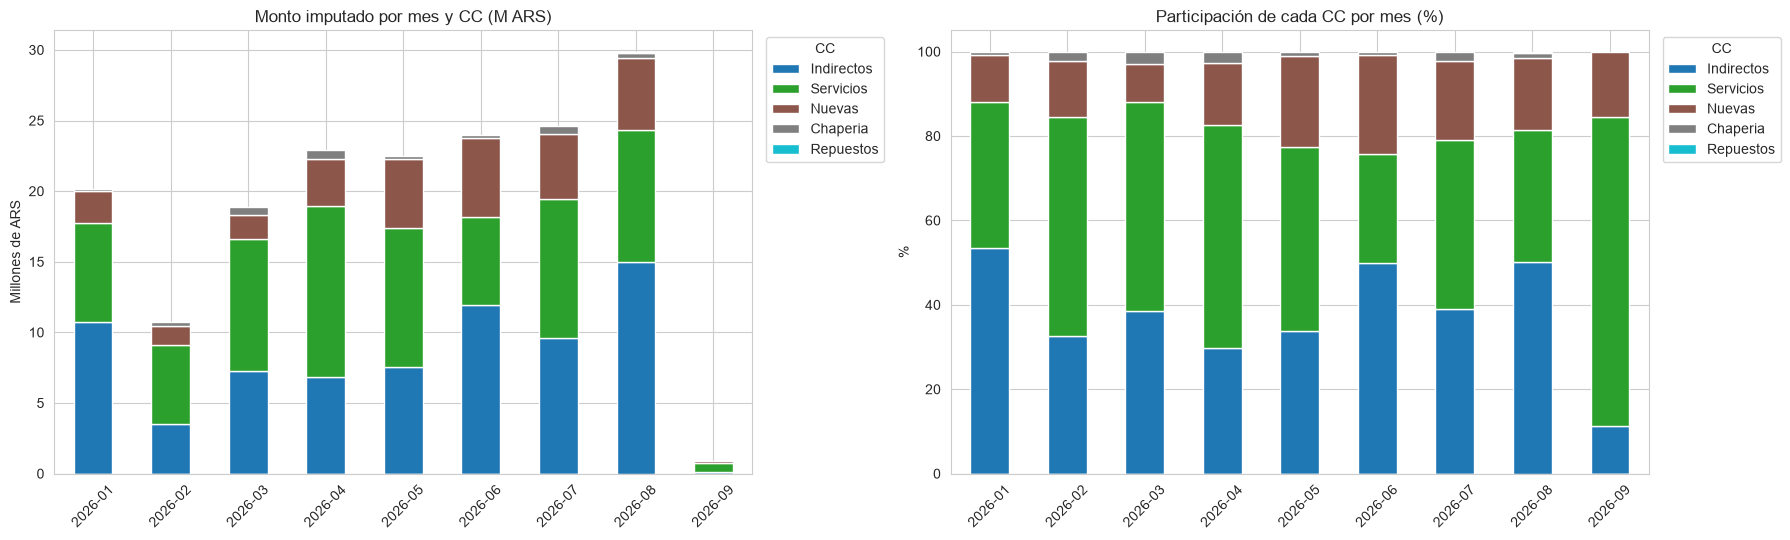

In [18]:
# ─────────────────────────────────────────────────────────────
# 8b. Desglose mensual por centro de costo (a partir de splits)
#     Matriz mes × CC (monto y cantidad) + barras apiladas + %.
# ─────────────────────────────────────────────────────────────
# Orden de columnas según monto total (descendente)
cc_order = [c for c in cc_split["total"].sort_values(ascending=False).index
            if c in sp["splitCC"].dropna().unique()]

# Monto y cantidad por (mes × CC)
cc_mensual = (sp.groupby(["month", "splitCC"], dropna=False)
                .agg(n=("uniqueCode", "count"),
                     total=("splitAmount", "sum"))
                .sort_index())
print("═══ Monto y cantidad imputada por CC y mes ═══")
print(cc_mensual.assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())

# Matriz mes × CC — monto total (ARS)
piv_total = (sp.pivot_table(index="month", columns="splitCC",
                            values="splitAmount", aggfunc="sum", fill_value=0)
               .reindex(columns=cc_order, fill_value=0))
print("\n═══ Matriz mes × CC — monto (ARS) ═══")
print(piv_total.map("${:,.0f}".format).to_string())

# Matriz mes × CC — cantidad de transacciones
piv_n = (sp.pivot_table(index="month", columns="splitCC",
                        values="uniqueCode", aggfunc="count", fill_value=0)
           .reindex(columns=cc_order, fill_value=0))
print("\n═══ Matriz mes × CC — cantidad de transacciones ═══")
print(piv_n.to_string())

# Gráficos: monto apilado por mes y participación (%)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
piv_total.div(1e6).plot(kind="bar", stacked=True, ax=axes[0],
                        colormap="tab10", edgecolor="white")
axes[0].set_title("Monto imputado por mes y CC (M ARS)")
axes[0].set_ylabel("Millones de ARS")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="CC", bbox_to_anchor=(1.01, 1), loc="upper left")

piv_share = piv_total.div(piv_total.sum(axis=1), axis=0) * 100
piv_share.plot(kind="bar", stacked=True, ax=axes[1],
               colormap="tab10", edgecolor="white")
axes[1].set_title("Participación de cada CC por mes (%)")
axes[1].set_ylabel("%")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="CC", bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()


## 9. Estados, aprobaciones y devoluciones

Distingue el gasto *confirmado* del que quedó *declined/pending/expired*, el estado del flujo de aprobación y las devoluciones/ajustes (signo positivo) que deberían compensarse.


In [19]:
# ─────────────────────────────────────────────────────────────
# 9. Estados y flujo de aprobación
# ─────────────────────────────────────────────────────────────
st = (tx.groupby("transactionStatus")
        .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
        .sort_values("total", ascending=False))
print("═══ Estado de la transacción ═══")
print(st.assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())

wf = (tx.groupby("approvalWorkflowStatus")
        .agg(n=("uniqueCode", "count"), total=("amount", "sum"))
        .sort_values("total", ascending=False))
print("\n═══ Flujo de aprobación ═══")
print(wf.assign(total=lambda d: d["total"].map("${:,.0f}".format)).to_string())

no_conf = tx[tx["transactionStatus"] != "CONFIRMED"]
print(f"\nTx NO confirmadas: {len(no_conf):,} | monto: ${no_conf['amount'].sum():,.0f}")

print("\n═══ Devoluciones y ajustes (sign > 0) ═══")
dev = tx[tx["sign"] > 0]
print(dev[["paymentDate", "paymentPayerFullName", "sellerName",
           "description", "amount"]].to_string(index=False))

print(f"\nCanceladas: {int(tx['cancelled'].sum())}")


═══ Estado de la transacción ═══
                      n         total
transactionStatus                    
CONFIRMED          3281  $160,000,837
DECLINED             84   $15,856,789
PENDING               1           $76
EXPIRED               3            $0

═══ Flujo de aprobación ═══
                           n         total
approvalWorkflowStatus                    
AUTHORIZED              3229  $157,249,077
SUBMITTED                 18      $669,393
PARTIAL_AUTHORIZED        14      $661,910
PENDING_SUBMISSION         7      $376,973
UNAUTHORIZED               4       $51,120
PENDING                    1            $0

Tx NO confirmadas: 88 | monto: $15,856,865

═══ Devoluciones y ajustes (sign > 0) ═══
                     paymentDate    paymentPayerFullName           sellerName          description     amount
2026-04-26 11:32:47.112000+00:00           Gustavo Ayala                Makro                Makro  18,436.07
2026-05-18 16:33:18.193000+00:00   Diego Nicolas Ortelli   

## 10. Presupuestos vs gasto real

Cruza `budgets.csv` (goal por persona) con el gasto real por pagador, para ver consumo del presupuesto y quiénes lo superan.


  budgets.csv                   394 filas × 10 cols
Presupuestos totales: 394 | activos: 384
cycleType
ONE_TIME         322
RECURRING         70
DAY_RECURRING      2

═══ Personas con presupuesto: consumo del goal ═══
                             budget_goal   gasto_real  consumo_pct    disponible
Martin Ojea Quintana         $70,000,000  $29,202,468        41.72   $40,797,532
Gustavo Ayala                 $8,731,500  $21,175,287       242.52  $-12,443,787
Juan Jose Echaire            $20,000,000   $9,253,617        46.27   $10,746,383
Claudio Marcelo Zvicer       $20,500,000   $8,427,897        41.11   $12,072,103
Juan Pablo Maldonado          $5,880,000   $7,294,955       124.06   $-1,414,955
Edgardo Barnetche            $70,000,000   $6,791,784         9.70   $63,208,216
Martin Miguel Fernandez      $10,822,105   $6,465,557        59.74    $4,356,549
Sebastián Carlos Cordoba     $20,400,000   $5,325,240        26.10   $15,074,760
Jorge Armando                $20,000,000   $4,693,843

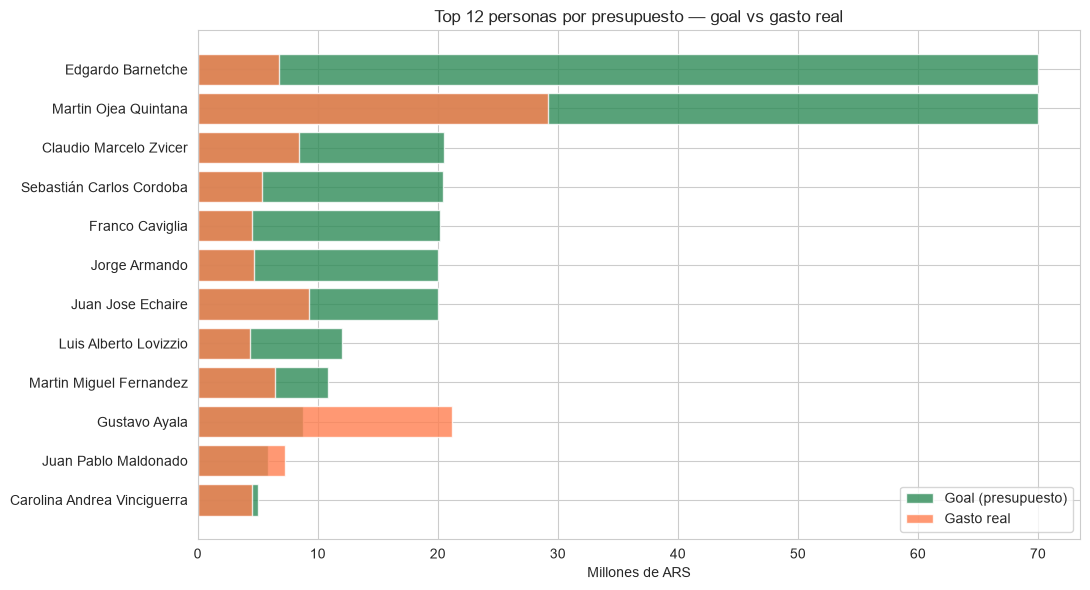

In [20]:
# ─────────────────────────────────────────────────────────────
# 10. Presupuestos (budgets) vs gasto real por persona
# ─────────────────────────────────────────────────────────────
budgets = load("budgets.csv")
budgets["goal"] = pd.to_numeric(budgets["goal"], errors="coerce")
budgets["active"] = to_bool(budgets["active"])

print(f"Presupuestos totales: {len(budgets):,} | activos: {int(budgets['active'].sum()):,}")
print(budgets["cycleType"].value_counts().to_string())

goal = budgets[budgets["active"]].groupby("personName")["goal"].sum()
spent = tx.groupby("paymentPayerFullName")["amount"].sum()

cmp_ = (pd.DataFrame({"budget_goal": goal, "gasto_real": spent})
          .dropna()
          .assign(consumo_pct=lambda d: d["gasto_real"] / d["budget_goal"] * 100,
                  disponible=lambda d: d["budget_goal"] - d["gasto_real"])
          .sort_values("gasto_real", ascending=False))
print("\n═══ Personas con presupuesto: consumo del goal ═══")
fmt = lambda v: f"${v:,.0f}" if pd.notna(v) else v
print(cmp_.assign(budget_goal=lambda d: d["budget_goal"].map(fmt),
                  gasto_real=lambda d: d["gasto_real"].map(fmt),
                  disponible=lambda d: d["disponible"].map(fmt)).head(15).to_string())
print(f"\nPersonas con consumo > 100% del goal: {int((cmp_['consumo_pct'] > 100).sum())}")

# Gráfico comparativo top 12
d = cmp_.head(12).sort_values("budget_goal")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(d.index, d["budget_goal"] / 1e6, color="seagreen", alpha=.8, label="Goal (presupuesto)")
ax.barh(d.index, d["gasto_real"] / 1e6, color="coral", alpha=.8, label="Gasto real")
ax.set_xlabel("Millones de ARS")
ax.set_title("Top 12 personas por presupuesto — goal vs gasto real")
ax.legend()
plt.tight_layout(); plt.show()


## 11. Documentación fiscal e IVA

`billing_documents.csv` tiene una fila por (comprobante × impuesto). Permite estimar el IVA involucrado y el mix de tipos de comprobante (Factura A, Tique, etc.).


  billing_documents.csv       6,705 filas × 19 cols
Filas de billing: 6,705 | comprobantes únicos: 4,530

═══ Tipos de comprobante (invoiceType) ═══
invoiceType
Facturas A                                                                           2794
Tique Factura A                                                                      2339
Tique                                                                                 453
Facturas B                                                                            377
Facturas C                                                                            374
Tique Factura B                                                                       107
Otros Comprobantes que No Cumplen o Están Exceptuados de la R.G. 1415 y sus Modif      48
Otros Comprobantes - Documentos Exceptuados - Notas de Crédito                         19
Recibos B                                                                              18
Tique Factura C              

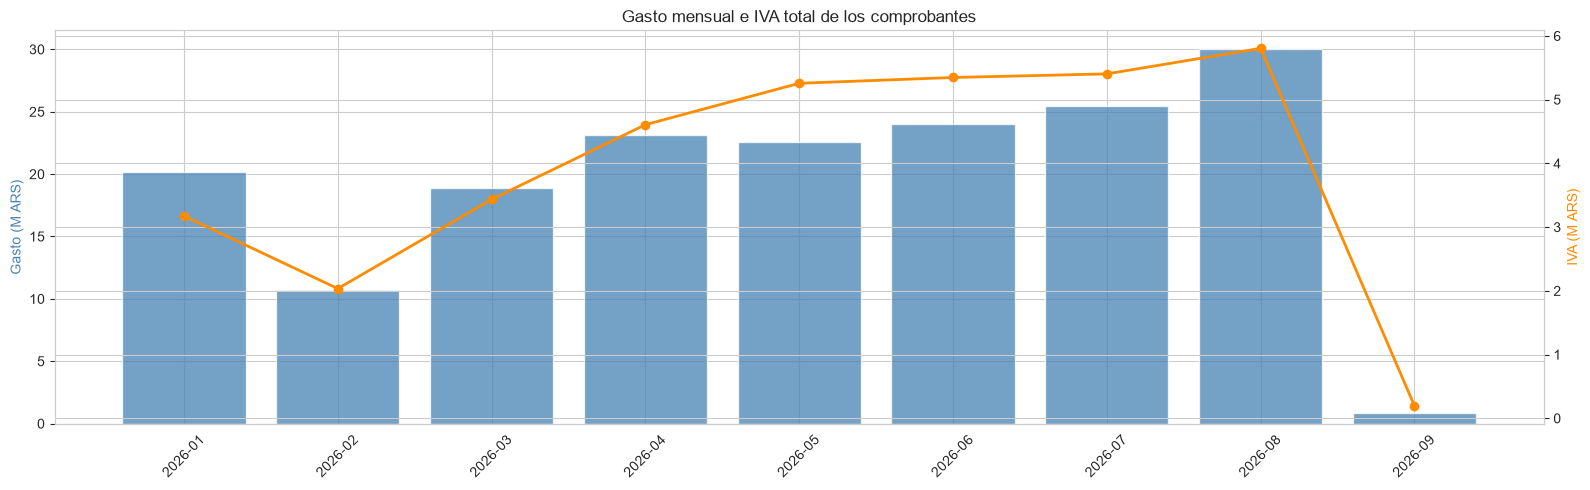

In [21]:
# ─────────────────────────────────────────────────────────────
# 11. Documentos fiscales e IVA (billing_documents)
# ─────────────────────────────────────────────────────────────
billing = load("billing_documents.csv")
for c in ["fiscalAmount", "taxAmount", "summaryTotalIva",
          "summaryTotalIngresosBrutos"]:
    billing[c] = pd.to_numeric(billing[c], errors="coerce")

print(f"Filas de billing: {len(billing):,} | comprobantes únicos: "
      f"{billing['purchaseUniqueCode'].nunique():,}")

print("\n═══ Tipos de comprobante (invoiceType) ═══")
print(billing["invoiceType"].value_counts().head(10).to_string())

print("\n═══ Impuestos (taxType × taxAmount) ═══")
print(billing.groupby("taxType")["taxAmount"]
             .agg(["count", "sum"]).sort_values("sum", ascending=False).to_string())

# IVA por mes (cruza por uniqueCode con el mes de la transacción)
b = billing.merge(tx[["uniqueCode", "month", "amount"]],
                  left_on="purchaseUniqueCode", right_on="uniqueCode", how="left")
iva_m = b.groupby("month")["summaryTotalIva"].sum()
print("\n═══ IVA total por mes ═══")
print(iva_m.map("${:,.0f}".format).to_string())

monthly2 = tx.groupby("month")["amount"].sum()
fig, ax1 = plt.subplots(figsize=(16, 5))
ax1.bar(monthly2.index, monthly2 / 1e6, color="steelblue", alpha=.75, label="Gasto (M ARS)")
ax1.set_ylabel("Gasto (M ARS)", color="steelblue"); ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(iva_m.index, iva_m / 1e6, "o-", color="darkorange", lw=2, label="IVA (M ARS)")
ax2.set_ylabel("IVA (M ARS)", color="darkorange")
ax1.set_title("Gasto mensual e IVA total de los comprobantes")
plt.tight_layout(); plt.show()


## 12. Resumen y próximos pasos

Los hallazgos numéricos se imprimen en la celda final. Ideas de profundización:

1. **Conciliación fiscal**: cruzar `billing_documents` por `purchaseUniqueCode` y detectar comprobantes faltantes (gasto sin factura).
2. **Heurística de pre-imputación**: por pagador+comercio+descripción → CC/concepto/cuenta históricos.
3. **Control de devoluciones**: verificar que cada REFUND tenga su compra asociada y el ticket.
4. **Seguimiento de presupuesto**: evolución mensual del consumo por presupuesto y alertas de >100%.
5. **Análisis de proveedores**: concentración de gasto (Pareto) por comercio y categoría.


In [22]:
# ─────────────────────────────────────────────────────────────
# 12. Resumen consolidado
# ─────────────────────────────────────────────────────────────
print("════════════════════════════════════════════════")
print("  MENDEL (CVC) — RESUMEN DE TRANSACCIONES")
print("════════════════════════════════════════════════")
print(f"  Transacciones:          {len(tx):>10,}")
print(f"  Gasto total (ARS):      {gasto:>15,.0f}")
print(f"  Créditos/devoluciones:  {creditos:>15,.0f}")
print(f"  Gasto neto (ARS):       {gasto - creditos:>15,.0f}")
print(f"  Ticket promedio (ARS):  {tx['amount'].mean():>15,.0f}")
print(f"  Pagadores:              {tx['paymentPayerFullName'].nunique():>10,}")
print(f"  Comercios:              {tx['sellerName'].nunique():>10,}")
print(f"  Mes con más gasto:      {monthly['total'].idxmax()} "
      f"({monthly['total'].max():,.0f} ARS)")
print(f"  CC principal (split):   {cc_split['total'].idxmax()} "
      f"({cc_split['total'].max():,.0f} ARS)")
print("════════════════════════════════════════════════")


════════════════════════════════════════════════
  MENDEL (CVC) — RESUMEN DE TRANSACCIONES
════════════════════════════════════════════════
  Transacciones:               3,369
  Gasto total (ARS):          174,878,879
  Créditos/devoluciones:          978,824
  Gasto neto (ARS):           173,900,055
  Ticket promedio (ARS):           52,199
  Pagadores:                      61
  Comercios:                     785
  Mes con más gasto:      2026-08 (30,011,039 ARS)
  CC principal (split):   Indirectos (72,568,234 ARS)
════════════════════════════════════════════════
